In [1]:
import pandas as pd

URL = "https://raw.githubusercontent.com/RoMarlene/TPI---Introduccion-al-analisis-de-datos---Comision-143-C2/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(URL)
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [2]:
import pandas as pd

URL = "https://raw.githubusercontent.com/RoMarlene/TPI---Introduccion-al-analisis-de-datos---Comision-143-C2/64e3442c326a6edd0aad586eb4647571693f6c92/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(URL)
dfCopia = df.copy()

dfCopia.to_csv("data/processed/telco_churn_limpio.csv", index=False)
print("Dataset guardado correctamente. Shape final:", d.shape)

pd.DataFrame(df)

OSError: Cannot save file into a non-existent directory: 'data/processed'

In [ ]:
df[
    [
        "PaymentMethod",
        "Churn",

    ]
].value_counts()


,,count
PaymentMethod,Churn,
Mailed check,No,1304
Electronic check,No,1294
Credit card (automatic),No,1290
Bank transfer (automatic),No,1286
Electronic check,Yes,1071
Mailed check,Yes,308
Bank transfer (automatic),Yes,258
Credit card (automatic),Yes,232


In [ ]:
df["cancelo"] = df["Churn"] == "Yes"      # True si canceló, False si no

tabla = df.groupby("PaymentMethod")["cancelo"].agg(["count", "sum", "mean"])
#print(tabla["mean"])
#print("====================")
tabla["mean"] = (tabla["mean"] * 100).round(2)
#print(tabla["mean"])
tabla = tabla.rename(columns={
    "count": "total",
    "sum": "cancelados",
    "mean": "tasa_churn_%",
})

tabla.sort_values("tasa_churn_%", ascending=False)

,total,cancelados,tasa_churn_%
PaymentMethod,,,
Electronic check,2365,1071,45.29
Mailed check,1612,308,19.11
Bank transfer (automatic),1544,258,16.71
Credit card (automatic),1522,232,15.24


In [ ]:
df["cancelo"] = df["Churn"] == "Yes"

clientes_menos_13 = df[df["tenure"] < 13]
clientes_mas_13 = df[df["tenure"] >= 13]

tabla = pd.DataFrame({
    "antiguedad": ["Menos de 13 meses", "13 meses o más"],
    "total": [
        clientes_menos_13["cancelo"].count(),
        clientes_mas_13["cancelo"].count()
    ],
    "cancelados": [
        clientes_menos_13["cancelo"].sum(),
        clientes_mas_13["cancelo"].sum()
    ],
    "tasa churn%": [
        (clientes_menos_13["cancelo"].mean() * 100).round(2),
        (clientes_mas_13["cancelo"].mean() * 100).round(2)
    ]
})

display(tabla)

,antiguedad,total,cancelados,tasa churn%
0,Menos de 13 meses,2186,1037,47.44
1,13 meses o más,4857,832,17.13


In [ ]:
#Data Cleaning
import numpy as np
import pandas as pd

# Cargar desde data/raw/ según la estructura del repo
URL = "https://raw.githubusercontent.com/RoMarlene/TPI---Introduccion-al-analisis-de-datos---Comision-143-C2/main/data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(URL)

print("Dimensiones:", df.shape)
print("\nTipos de datos (dtypes):")
print(df.dtypes)

print("\nNulos explícitos (.isna()):")
print(df.isna().sum()[df.isna().sum() > 0])

print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs únicos:", df["customerID"].nunique())

Dimensiones: (7043, 21)

Tipos de datos (dtypes):
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Nulos explícitos (.isna()):
Series([], dtype: int64)

Filas duplicadas: 0
IDs únicos: 7043


In [ ]:
tabla = df.loc[
    df["Churn"] == "Yes",
    ["customerID", "MonthlyCharges", "TotalCharges"]
]

display(tabla)

#convierto los valores object de la columna TotalCharges a números
#Si no hacemos la asignación, la conversión no queda aplicada permanentemente a la columna de df
df["TotalCharges"] = pd.to_numeric(
    df["TotalCharges"],
    #errors="coerce" #si hay un valor invalidO, Pandas lo convierte a NaN(valor ausente)
)

comparacion = df.groupby("Churn").agg(
    cantidad_clientes=("customerID", "count"), #cuenta cuantos clientes hay en cada grupo
    promedio_mensual=("MonthlyCharges", "mean"), #calcula el promedio de cuanto pagan MENSUALMENTE los clientes de cada grupo
    promedio_total=("TotalCharges", "mean") #calcula el promedio de cuanto pagan en TOTAL los clientes de cada grupo
)

display(comparacion)

,customerID,MonthlyCharges,TotalCharges
2,3668-QPYBK,53.85,108.15
4,9237-HQITU,70.70,151.65
5,9305-CDSKC,99.65,820.5
8,7892-POOKP,104.80,3046.05
13,0280-XJGEX,103.70,5036.3
...,...,...,...
7021,1699-HPSBG,59.80,727.8
7026,8775-CEBBJ,44.20,403.35
7032,6894-LFHLY,75.75,75.75
7034,0639-TSIQW,102.95,6886.25


,cantidad_clientes,promedio_mensual,promedio_total
Churn,,,
No,5174,61.265124,2555.344141
Yes,1869,74.441332,1531.796094


In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].describe().round(2)


,tenure,MonthlyCharges,TotalCharges
count,7043.00,7043.00,7032.00
mean,32.37,64.76,2283.30
std,24.56,30.09,2266.77
min,0.00,18.25,18.80
25%,9.00,35.50,401.45
50%,29.00,70.35,1397.48
75%,55.00,89.85,3794.74
max,72.00,118.75,8684.80


In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].mode()

,tenure,MonthlyCharges,TotalCharges
0,1,20.05,20.2


In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].var().round(2)

,0
tenure,603.17
MonthlyCharges,905.41
TotalCharges,5138252.41


In [ ]:
q1 = df[["tenure", "MonthlyCharges", "TotalCharges"]].quantile(0.25)
q3 =  df[["tenure", "MonthlyCharges", "TotalCharges"]].quantile(0.75)
iqr = q3 - q1
display(iqr)

,0
tenure,46.0000
MonthlyCharges,54.3500
TotalCharges,3393.2875


In [ ]:
df[["tenure", "MonthlyCharges", "TotalCharges"]].max() - df[["tenure", "MonthlyCharges", "TotalCharges"]].min()

,0
tenure,72.0
MonthlyCharges,100.5
TotalCharges,8666.0


NaN con tenure > 0 (debería dar 0): 0
Filas: 7043 | NaN restantes: 0
                tenure  MonthlyCharges  TotalCharges
tenure            1.00            0.25          0.83
MonthlyCharges    0.25            1.00          0.65
TotalCharges      0.83            0.65          1.00


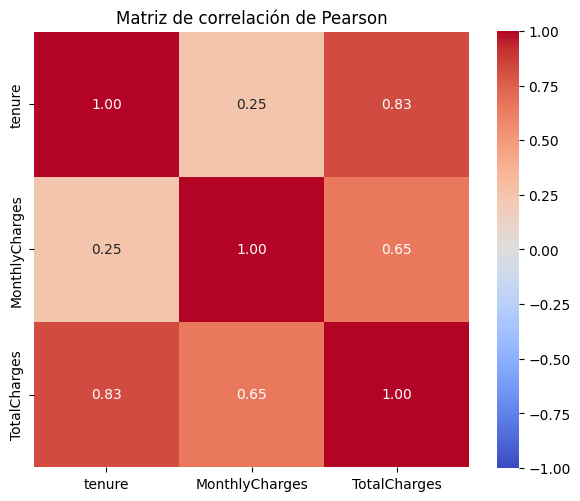

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

d = df.copy()
d["TotalCharges"] = pd.to_numeric(d["TotalCharges"], errors="coerce")

print("NaN con tenure > 0 (debería dar 0):", (d["TotalCharges"].isna() & (d["tenure"] > 0)).sum())

d.loc[d["TotalCharges"].isna() & (d["tenure"] == 0), "TotalCharges"] = 0

print("Filas:", len(d), "| NaN restantes:", d["TotalCharges"].isna().sum())

corr = d[["tenure", "MonthlyCharges", "TotalCharges"]].corr(method="pearson")
print(corr.round(2))

plt.figure(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Matriz de correlación de Pearson")
plt.tight_layout()
plt.show()

In [3]:
#Variables sociodemográficas
variables_sociodemograficas = [
    "gender",
    "SeniorCitizen",
    "Partner",
    "Dependents"
]

#Variables relacionadas con la contratación
variables_contratacion = [
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]


In [4]:
print(" FRECUENCIAS ABSOLUTAS - SOCIODEMOGRÁFICAS ")

for variable in variables_sociodemograficas:
    print(f"\nFrecuencia absoluta de {variable}:")
    tbl_absoluta_1 = df[variable].value_counts()
    display(tbl_absoluta_1)

print("------------------------------------------------")

print(" FRECUENCIAS ABSOLUTAS - CONTRATACIÓN ")
for variable in variables_contratacion:
    print(f"\nFrecuencia absoluta de {variable}:")
    tbl_absoluta_2 = df[variable].value_counts()
    display(tbl_absoluta_2)

 FRECUENCIAS ABSOLUTAS - SOCIODEMOGRÁFICAS 

Frecuencia absoluta de gender:


,count
gender,
Male,3555
Female,3488



Frecuencia absoluta de SeniorCitizen:


,count
SeniorCitizen,
0,5901
1,1142



Frecuencia absoluta de Partner:


,count
Partner,
No,3641
Yes,3402


... (22 outputs left out)


Frecuencia absoluta de PaperlessBilling:


,count
PaperlessBilling,
Yes,4171
No,2872



Frecuencia absoluta de PaymentMethod:


,count
PaymentMethod,
Electronic check,2365
Mailed check,1612
Bank transfer (automatic),1544
Credit card (automatic),1522


In [5]:
print(" FRECUENCIAS RELATIVAS - SOCIODEMOGRÁFICAS ")

for variable in variables_sociodemograficas:
    print(f"\nFrecuencia relativa de {variable}:")
    tbl_relativa_1 = df[variable].value_counts(normalize=True) * 100
    display(
        tbl_relativa_1.round(2)
        .to_frame() # Convierte Series object en un df de una sola columna
        .style.format("{:.2f}%"))

print("------------------------------------------------")

print(" FRECUENCIAS RELATIVAS - CONTRATACIÓN ")
for variable in variables_contratacion:
    print(f"\nFrecuencia relativa de {variable}:")
    tbl_relativa_2 = df[variable].value_counts(normalize=True) * 100
    display(
        tbl_relativa_2
        .round(2)
        .to_frame()
        .style.format("{:.2f}%"))


 FRECUENCIAS RELATIVAS - SOCIODEMOGRÁFICAS 

Frecuencia relativa de gender:


,proportion
gender,
Male,50.48%
Female,49.52%



Frecuencia relativa de SeniorCitizen:


,proportion
SeniorCitizen,
0,83.79%
1,16.21%



Frecuencia relativa de Partner:


,proportion
Partner,
No,51.70%
Yes,48.30%


... (22 outputs left out)


Frecuencia relativa de PaperlessBilling:


,proportion
PaperlessBilling,
Yes,59.22%
No,40.78%



Frecuencia relativa de PaymentMethod:


,proportion
PaymentMethod,
Electronic check,33.58%
Mailed check,22.89%
Bank transfer (automatic),21.92%
Credit card (automatic),21.61%


In [6]:
print(" TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - SOCIODEMOGRÁFICAS ")

for variable in variables_sociodemograficas:

    print(f"\nTabla de contingencia: {variable} vs Churn")

    # Frecuencias absolutas
    print("\nFrecuencias absolutas:")
    tabla_absoluta = pd.crosstab(df[variable], df["Churn"])
    display(tabla_absoluta)


    # Frecuencias relativas
    print("\nFrecuencias relativas:")
    tabla_relativa = pd.crosstab(df[variable], df["Churn"], normalize="index") * 100
    display(tabla_relativa.round(2).style.format("{:.2f}%"))


    print("-----------------------------------------------")


 TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - SOCIODEMOGRÁFICAS 

Tabla de contingencia: gender vs Churn

Frecuencias absolutas:


Churn,No,Yes
gender,,
Female,2549,939
Male,2625,930



Frecuencias relativas:


Churn,No,Yes
gender,,
Female,73.08%,26.92%
Male,73.84%,26.16%


-----------------------------------------------

Tabla de contingencia: SeniorCitizen vs Churn

Frecuencias absolutas:


Churn,No,Yes
SeniorCitizen,,
0,4508,1393
1,666,476


... (7 outputs left out)

Churn,No,Yes
Dependents,,
No,3390,1543
Yes,1784,326



Frecuencias relativas:


Churn,No,Yes
Dependents,,
No,68.72%,31.28%
Yes,84.55%,15.45%


-----------------------------------------------


In [7]:
print(" TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - CONTRATACIÓN ")

for variable in variables_contratacion:

    print(f"\nTabla de contingencia: {variable} vs Churn")

    # Frecuencias absolutas
    print("\nFrecuencias absolutas:")
    tabla_absoluta = pd.crosstab(df[variable], df["Churn"])
    display(tabla_absoluta)


    # Frecuencias relativas
    print("\nFrecuencias relativas:")
    tabla_relativa = pd.crosstab(df[variable], df["Churn"], normalize="index") * 100
    display(tabla_relativa.round(2).style.format("{:.2f}%"))

    print("-----------------------------------------------")

 TABLAS DE CONTINGENCIA CON FRECUENCIAS ABSOLUTAS Y RELATIVAS - CONTRATACIÓN 

Tabla de contingencia: PhoneService vs Churn

Frecuencias absolutas:


Churn,No,Yes
PhoneService,,
No,512,170
Yes,4662,1699



Frecuencias relativas:


Churn,No,Yes
PhoneService,,
No,75.07%,24.93%
Yes,73.29%,26.71%


-----------------------------------------------

Tabla de contingencia: MultipleLines vs Churn

Frecuencias absolutas:


Churn,No,Yes
MultipleLines,,
No,2541,849
No phone service,512,170
Yes,2121,850


... (39 outputs left out)

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),1286,258
Credit card (automatic),1290,232
Electronic check,1294,1071
Mailed check,1304,308



Frecuencias relativas:


Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29%,16.71%
Credit card (automatic),84.76%,15.24%
Electronic check,54.71%,45.29%
Mailed check,80.89%,19.11%


-----------------------------------------------


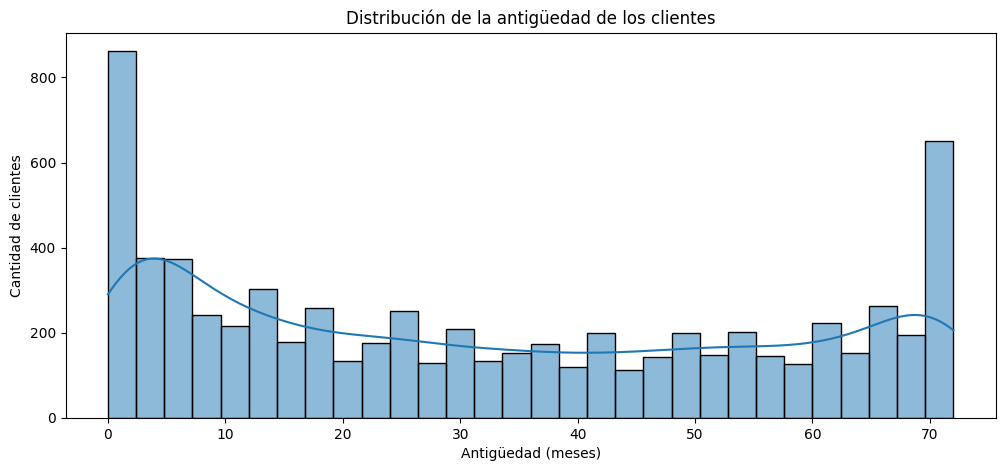

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

#Configurar el tamaño de los gráficos
plt.figure(figsize=(12, 5))

#Histograma y KDE de tenure
sns.histplot(
    data=df,
    x="tenure",
    kde=True, # Agrega la curva de densidad KDE
    bins=30 # definimos la cantidad de intervalos (barras) del gráfico
)

plt.title("Distribución de la antigüedad de los clientes")
plt.xlabel("Antigüedad (meses)")
plt.ylabel("Cantidad de clientes")
plt.show()

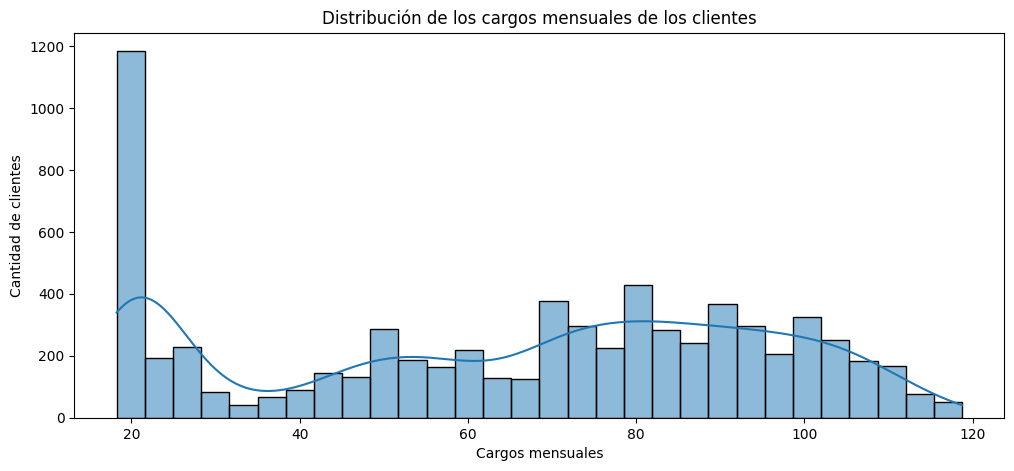

In [10]:
# Histograma y KDE de MonthlyCharges
plt.figure(figsize=(12, 5))

sns.histplot(
    data=df,
    x="MonthlyCharges",
    kde=True,
    bins=30
)

plt.title("Distribución de los cargos mensuales de los clientes")
plt.xlabel("Cargos mensuales")
plt.ylabel("Cantidad de clientes")
plt.show()

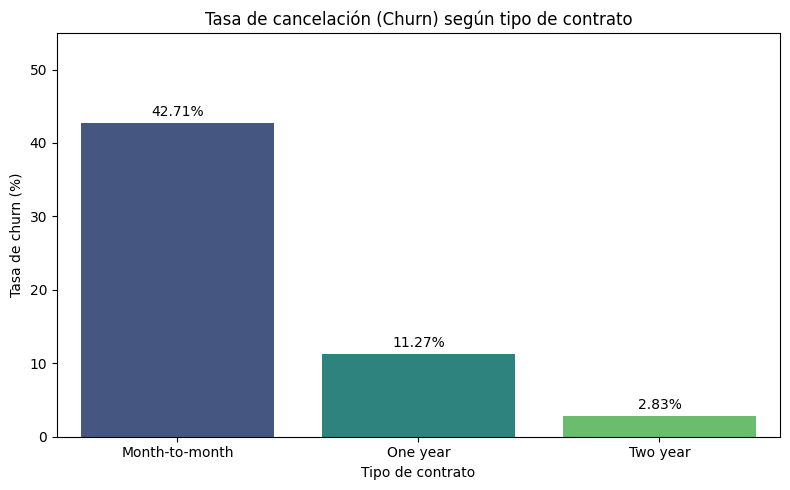

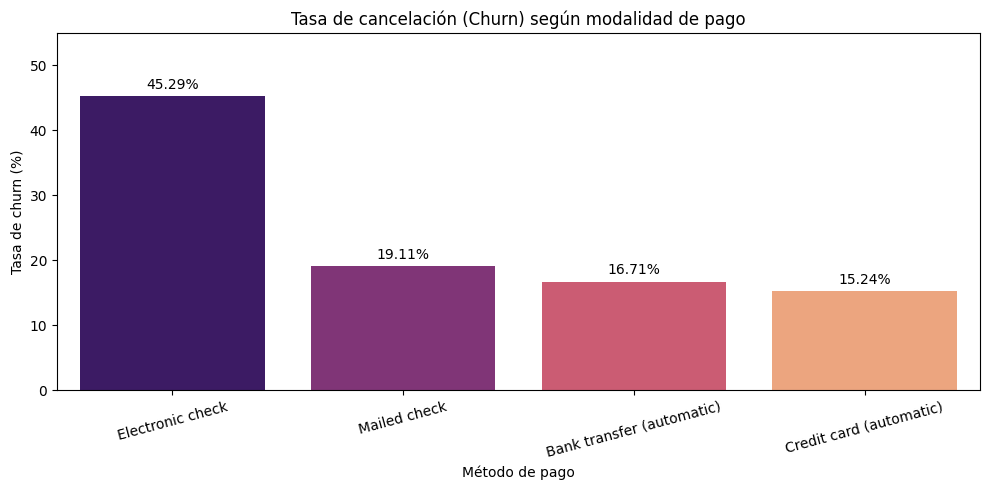

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Columna numérica de churn (1 = canceló, 0 = no)
df["cancelo"] = (df["Churn"] == "Yes").astype(int)

# ---------- Gráfico 1: Churn por tipo de contrato ----------
churn_contrato = (
    df.groupby("Contract")["cancelo"].mean() * 100
).sort_values(ascending=False).reset_index()
churn_contrato.columns = ["Contract", "tasa_churn"]

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=churn_contrato, x="Contract", y="tasa_churn",
                 hue="Contract", palette="viridis", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.title("Tasa de cancelación (Churn) según tipo de contrato")
plt.xlabel("Tipo de contrato")
plt.ylabel("Tasa de churn (%)")
plt.ylim(0, 55)
plt.tight_layout()
plt.show()

# ---------- Gráfico 2: Churn por modalidad de pago ----------
churn_pago = (
    df.groupby("PaymentMethod")["cancelo"].mean() * 100
).sort_values(ascending=False).reset_index()
churn_pago.columns = ["PaymentMethod", "tasa_churn"]

plt.figure(figsize=(10, 5))
ax = sns.barplot(data=churn_pago, x="PaymentMethod", y="tasa_churn",
                 hue="PaymentMethod", palette="magma", legend=False)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)
plt.title("Tasa de cancelación (Churn) según modalidad de pago")
plt.xlabel("Método de pago")
plt.ylabel("Tasa de churn (%)")
plt.ylim(0, 55)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()